# HomeWork 2 - diabetes-health-indicators

## Importações de bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os
import math
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_squared_error, r2_score

## Baixando Dataset

In [ ]:
# Download latest version
path = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")

print("Path to dataset files:", path)
os.listdir(path)

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-health-indicators-dataset


['diabetes_binary_5050split_health_indicators_BRFSS2015.csv',
 'diabetes_binary_health_indicators_BRFSS2015.csv',
 'diabetes_012_health_indicators_BRFSS2015.csv']

## Tratando o dataset

In [ ]:
df = pd.read_csv(f'{path}/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
#ramdomizando para ficarmos com as 6000 primeiras com media 0.5
df_random = df.sample(frac=1, random_state=42).reset_index(drop=True)

#tratando dados duplicados -> parece haver poucos
df_random.duplicated()
df_random.drop_duplicates(inplace=True)

#pegando as 6000
df_6000 = df_random.iloc[:6000].copy()

## Análise do Dataset
O dataset utilizado contém dados acerca de indicadores de saúde relacionados à diabetes de múltiplos indivíduos. A quantidade de amostras utilizadas para a análise contida nesse notebook se limita a $N = 6000$. Além disso, o dataset contém $D=21$ colunas/preditores e como saída o Índice de Massa Corporal (BMI).

Assimetria:
BMI         1.683556
PhysHlth    1.616705
MentHlth    2.395246
dtype: float64


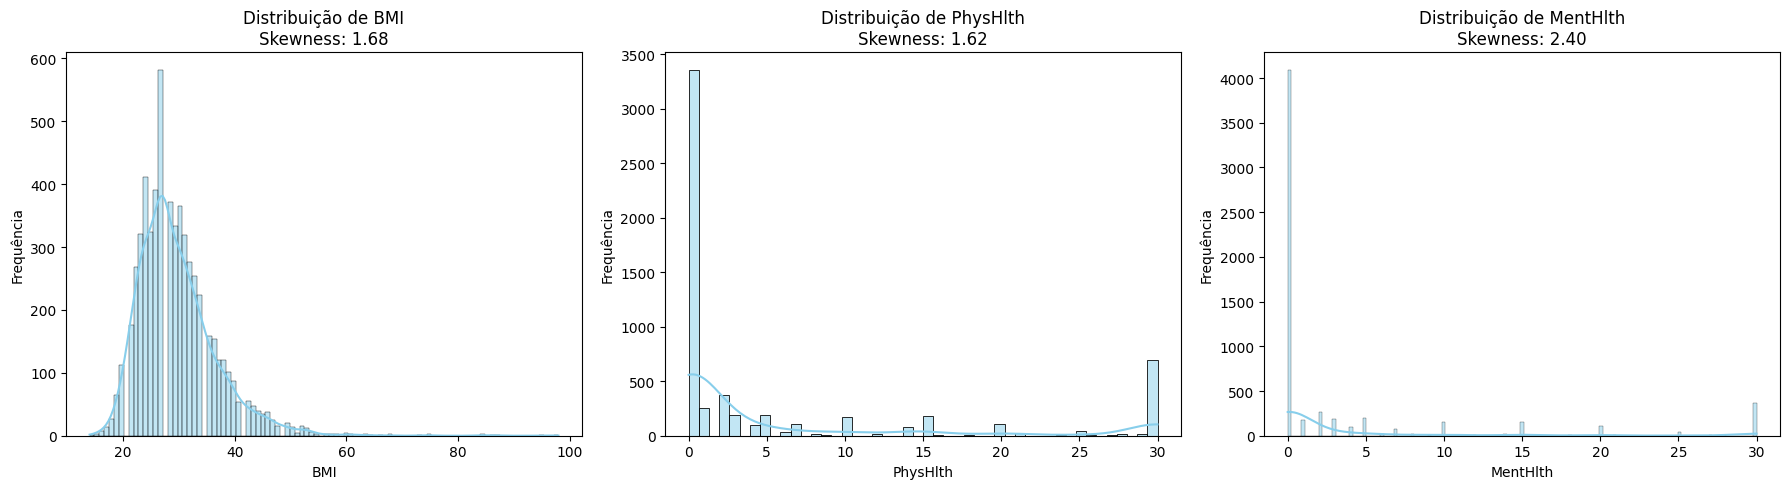

In [ ]:
# Análise de assimetria dos preditores quantitativos

# No nosso caso, as variáveis quantitativas contínuas são 'BMI', 'PhysHlth' e 'MentHlth'
colunas_quantitativas = ['BMI', 'PhysHlth', 'MentHlth']

# Calculando a assimetria (skewness) para cada preditor quantitativo
skewness = df_6000[colunas_quantitativas].skew()
print("Assimetria:")
print(skewness)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(colunas_quantitativas):
    sns.histplot(df_6000[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribuição de {col}\nSkewness: {skewness[col]:.2f}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

Os três preditores quatitativos apresentaram valores significativos de assimetria positiva \(BMI: **1.6836**, PhysHlth: **1.6167** e MentHlth: **2.3952**\). Logo, é justificável aplicar transformações para tratamento de skewness em todos esses preditores para estabilizar a variância e se aproximar de uma distribuição normal.

In [ ]:
# Transformação Yeo-Johnson (Alternativa ao Box-Cox que aceita zeros e valores negativos)
def tratamento_skewness(df, lambdas=None):
    df = df.copy()

    if lambdas is None:
        lambdas = {}

        for col in ['PhysHlth', 'MentHlth']:
            if col in df.columns:
                df[col], lambdas[col] = stats.yeojohnson(df[col])

    else:
        for col in ['PhysHlth', 'MentHlth']:
            if col in df.columns:
                df[col] = stats.yeojohnson(
                    df[col],
                    lmbda=lambdas[col]
                 )
    return df, lambdas

## Modelo OLS

Utilize os preditores transformados no conjunto de treinamento para ajustar um modelo de regressão por mínimos quadrados ordinários (MQO) e teste o modelo usando o conjunto de teste (lembre-se de aplicar o mesmo pré-processamento utilizado no conjunto de treinamento). Implemente o modelo de MQO do zero e compare os resultados obtidos com aqueles gerados por funções nativas (já existentes) na linguagem de programação de sua escolha. Compare o desempenho do modelo no conjunto de teste com as estimativas que seriam obtidas por meio de um esquema de reamostragem, como a validação cruzada de 5 ou 10 partições (*k-fold cross-validation*); utilize tanto o RMSE quanto o R² (novamente, implemente a validação cruzada do zero e compare os resultados com aqueles obtidos por meio de uma função nativa).

### Separando o conjunto de dados

In [ ]:
#separando em treino e teste
idx_corte = int(len(df_6000)*0.75)

# Inserindo uma com valor 1 na posição 0 (1ª coluna)
df_6000.insert(loc=0, column="b0", value=1)

# df_treino definido como os primeiros 75% valores do dataset reduzido (com 6000 valores)
df_treino = df_6000[:idx_corte]

# df_teste como os últimos 25% valores do dataset reduzido
df_teste = df_6000[idx_corte:]

### Definindo Funções

In [ ]:
#FUNÇÃO PARA CALCULO DO R²
def r2_calculo(y_treino, y_hat):
  RSS = ((y_treino - y_hat) ** 2).sum()
  TSS = ((y_treino - y_treino.mean()) ** 2).sum()
  R2 = 1 - (RSS / TSS)
  return R2

In [ ]:
#FUNÇÃO PARA CALCULO DO MSE
def MSE_calculo(y_treino, y_hat):
  RSS = ((y_treino - y_hat) ** 2).sum()
  MSE = RSS / len(y_treino)
  return MSE

In [ ]:
#FUNÇÃO PARA CALCULO DO RMSE
def RMSE_calculo(y_treino, y_hat):
  RMSE =  math.sqrt(MSE_calculo(y_treino, y_hat))
  return RMSE

In [ ]:
#função para verificar se é inversivel
def eh_inversivel(XTX: np.ndarray) -> bool:
  if np.linalg.matrix_rank(XTX) == XTX.shape[1]:
    # print("é inversível")
    return True
  else:
    print("não é inversível")
    print(np.linalg.matrix_rank(XTX))
    return False

In [ ]:
def meu_OLS(X: np.ndarray, y: np.ndarray, lambd = 0):
  XTX = (X.T @ X)
  I = np.identity(len(XTX))
  I[0, 0] = 0
  XTXp = XTX + +(lambd * I)
  if eh_inversivel(XTXp):
    XTX_inv = np.linalg.inv(XTXp)
    b_hat = XTX_inv @ X.T @ y
    return b_hat
  else:
    return None

In [ ]:
# Função para remover outliers
def remover_outliers(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    return df[
        df[coluna].between(limite_inferior, limite_superior)
    ].copy()


### Treinando e testando o modelo OLS

In [ ]:
#IDENTANDO AS MATRIZES X E Y E B^ PARA CALCULOS
X_treino = df_treino.drop(columns=['BMI'])
X_teste = df_teste.drop(columns=['BMI'])
y_treino = df_treino['BMI']
y_teste = df_teste['BMI']

In [ ]:
#dados com skewness tratados
X_treino, lambdas = tratamento_skewness(X_treino)
X_teste, _ = tratamento_skewness(X_teste, lambdas)

b_hat = meu_OLS(X_treino, y_treino)

In [ ]:
#TESTANDO O MODELO NO TREINO
y_hat = X_treino @ b_hat.values
R2 = r2_calculo(y_treino, y_hat)
print(f"Métrica R2: {R2:5g}")

Métrica R2: 0.177024


In [ ]:
#TESTANDO O MODELO NO TESTE
y_hat = X_teste @ b_hat.values

R2 = r2_calculo(y_teste, y_hat)
print(f"Métrica R2: {R2:5g}")

Métrica R2: 0.225681


### Validação do cálculo do OLS

In [ ]:
#VALIDANDO COM FUNÇÃO PRONTA
b_hat_np, _, _, _ = np.linalg.lstsq(X_treino, y_treino, rcond=None)
y_hat_np = X_teste @ b_hat_np
R2_np = r2_calculo(y_teste, y_hat_np)
print(R2_np)
print(R2-R2_np)

0.22568070981786692
-7.771561172376096e-15


### Validação com k_fold

In [ ]:
def k_fold_cv(X: pd.DataFrame, y: pd.DataFrame, k: int, shuffle: bool=False, seed: int=32, lambd=0):
  """
  Função que implementa a validação cruzada k-fold para regressão linear.
  A saída é um vetor de scores de métrica do modelo (R2 na primeira coluna e RMSE na segunda).
  """

  # Ajuste de DataFrame do pandas para ndarray do numpy para
  # melhor eficiência no cálculo matricial
  X = np.asarray(X, dtype=np.float64)
  y = np.asarray(y, dtype=np.float64).ravel()

  n = X.shape[0]
  idx = np.arange(n)

  # No k fold cross validation, as amostras são particionadas aleatoriamente
  if shuffle:
    np.random.seed(seed)
    np.random.shuffle(idx)

  # Separa os índices do dataset em k partes
  folds = np.array_split(idx, k)

  scores = np.zeros((k, 2))

  for fold_idx in range(k):
    # O conjunto atual para validação
    valid_idx = folds[fold_idx]

    # O restante é para treino
    train_idx = np.concatenate([folds[i] for i in range(k) if i != fold_idx])

    X_train, y_train = X[train_idx], y[train_idx]
    X_valid, y_valid = X[valid_idx], y[valid_idx]

    b_hat = meu_OLS(X_train, y_train, lambd)

    y_hat = X_valid @ b_hat
    R2 = r2_calculo(y_valid, y_hat)
    RMSE = RMSE_calculo(y_valid, y_hat)

    scores[fold_idx, 0] = R2
    scores[fold_idx, 1] = RMSE

  return scores

In [ ]:
scores_5 = k_fold_cv(X_treino, y_treino, 5, shuffle=True)
scores_10 = k_fold_cv(X_treino, y_treino, 10, shuffle=True)
# print(scores_10)
# print(scores_5)
print("------ Resultados para 5 folds --------")
print(f"Média de R2:           {scores_5[:, 0].mean():5g}")
print(f"Desvio padrão de R2:   {np.std(scores_5[:,0]):5g}")
print(f"Média de RMSE:         {scores_5[:, 1].mean():5g}")
print(f"Desvio padrão de RMSE: {np.std(scores_5[:,1]):5g}\n")
print("------ Resultados para 10 folds --------")
print(f"Média de R2:           {scores_10[:, 0].mean():5g}")
print(f"Desvio padrão de R2:   {np.std(scores_10[:,0]):5g}")
print(f"Média de RMSE:         {scores_10[:, 1].mean():5g}")
print(f"Desvio padrão de RMSE: {np.std(scores_10[:,1]):5g}\n")


------ Resultados para 5 folds --------
Média de R2:           0.168852
Desvio padrão de R2:   0.0356743
Média de RMSE:         6.41223
Desvio padrão de RMSE: 0.244816

------ Resultados para 10 folds --------
Média de R2:           0.16902
Desvio padrão de R2:   0.0426597
Média de RMSE:         6.40294
Desvio padrão de RMSE: 0.41892



## Modelo penalizado

Utilize os preditores transformados no conjunto de treinamento para ajustar um modelo de regressão linear com penalização L2 (ou L1) e avalie o modelo usando o conjunto de teste (lembre-se de aplicar o mesmo pré-processamento utilizado no conjunto de treinamento). Implemente o modelo penalizado do zero e compare os resultados obtidos com aqueles gerados por funções nativas (já existentes) na linguagem de programação de sua escolha. Determine o valor ideal de λ por meio de validação cruzada de 5 ou 10 partições (*k-fold cross-validation*), com base no RMSE (nesta etapa, utilize apenas o conjunto de treinamento; o espaço de busca para λ deve conter, pelo menos, 10 valores). Descreva o processo (apresente o perfil da validação cruzada, tanto em termos de RMSE quanto de R²). Informe a precisão (RMSE e R²) obtida no conjunto de teste (novamente, implemente a validação cruzada do zero e compare os resultados com aqueles obtidos por meio de funções nativas).

In [ ]:
#tratando o Dataset
dfp_6000 = df_6000.copy()


#predditores
#dfp_6000 = dfp_6000.drop(['Age', 'Sex', 'NoDocbcCost', 'AnyHealthcare', 'HvyAlcoholConsump', 'Veggies', 'HeartDiseaseorAttack','Smoker',	'Stroke', 'CholCheck'	], axis=1)


In [ ]:
#DEFININDO PARAMETROS
#separando em treino e teste
idx_corte = int(len(dfp_6000)*0.75)

# df_treino definido como os primeiros 75% valores do dataset reduzido (com 6000 valores)
dfp_treino = dfp_6000[:idx_corte]
# Remover outliers de BMI
#dfp_treino = remover_outliers(dfp_treino, "BMI")

# df_teste como os últimos 25% valores do dataset reduzido
dfp_teste = dfp_6000[idx_corte:]

Xp_treino = dfp_treino.drop(columns=['BMI'])
Xp_teste = dfp_teste.drop(columns=['BMI'])
Yp_treino = dfp_treino['BMI']
Yp_teste = dfp_teste['BMI']
lambd = [0, 0.1, 1, 5, 10, 20, 50, 100, 500, 1000, 5000]
print(len(Xp_teste))

1500


In [ ]:
#FUNÇÃO PAARA CALCULAR K-FOLD
def kfold_media(X: pd.DataFrame, y: pd.DataFrame, k: int, shuffle: bool=False, seed: int=32, lambd=0):
  scores = k_fold_cv(X, y, k, shuffle, seed, lambd)
  score_R2_media = scores[:, 0].mean();
  score_RMSE_media = scores[:, 1].mean();
  return score_R2_media, score_RMSE_media

In [ ]:
#CALCULO DO RIDGE NA MÃO
parametres = pd.DataFrame(columns=[
    "lambda",
    "RMSE_k_fold_mao", "RMSE_k_fold_func","RMSE_mao", "RMSE_func",
    "R2_k_fold_mao", "R2_k_fold_func", "R2_mao", "R2_func"
])
fold = 10

for j in lambd:
  #criando modelo
  bp_hat = meu_OLS(Xp_treino, Yp_treino, j)
  #previsão
  yp_hat = Xp_teste @ bp_hat.values

  #CALCULO DO RIDGE POR FUNÇÃO
  # Criar o modelo
  modelo = Ridge(alpha=j)
  modelo.fit(Xp_treino, Yp_treino)

  # Fazer previsões
  yp_pred = modelo.predict(Xp_teste)

  #VALIDANDO
  RMSE_mao = RMSE_calculo(Yp_teste, yp_hat)
  R2_mao = r2_calculo(Yp_teste, yp_hat)

  RMSE_func = RMSE_calculo(Yp_teste, yp_pred)
  R2_func = r2_calculo(Yp_teste, yp_pred)

  #K-FOLD MÃO
  score_k_fold =  kfold_media(Xp_treino, Yp_treino, fold, True, 32, j)

  #K-FOLD FUNÇÃO
  # Definindo 5 folds
  cv = KFold(n_splits=fold, shuffle=True, random_state=42)

  # Executando validação cruzada
  resultados = cross_validate(modelo, Xp_treino, Yp_treino,  cv=cv, scoring=["neg_root_mean_squared_error", "r2"])

  # Resultados médios
  RMSE = -np.mean(resultados["test_neg_root_mean_squared_error"])
  R2 = np.mean(resultados["test_r2"])

  #colocando no dataframe
  parametres.loc[len(parametres)] = [
    j,
    score_k_fold[1], RMSE, RMSE_mao, RMSE_func,
    score_k_fold[0], R2, R2_mao, R2_func
  ]

display(parametres)


,lambda,RMSE_k_fold_mao,RMSE_k_fold_func,RMSE_mao,RMSE_func,R2_k_fold_mao,R2_k_fold_func,R2_mao,R2_func
0,0.0,6.402450,6.410627,6.198730,6.198730,0.169147,0.166247,0.226672,0.226672
1,0.1,6.402443,6.410614,6.198747,6.198747,0.169149,0.166250,0.226668,0.226668
2,1.0,6.402383,6.410499,6.198900,6.198900,0.169165,0.166281,0.226630,0.226630
3,5.0,6.402136,6.410026,6.199581,6.199581,0.169229,0.166411,0.226460,0.226460
4,10.0,6.401880,6.409509,6.200441,6.200441,0.169296,0.166552,0.226245,0.226245
5,20.0,6.401517,6.408693,6.202186,6.202186,0.169390,0.166775,0.225810,0.225810
6,50.0,6.401345,6.407517,6.207568,6.207568,0.169435,0.167104,0.224465,0.224465
7,100.0,6.403038,6.408170,6.216841,6.216841,0.168995,0.166953,0.222147,0.222147
8,500.0,6.440627,6.443265,6.289852,6.289852,0.159185,0.157789,0.203769,0.203769
9,1000.0,6.489633,6.491403,6.363477,6.363477,0.146303,0.145111,0.185020,0.185020


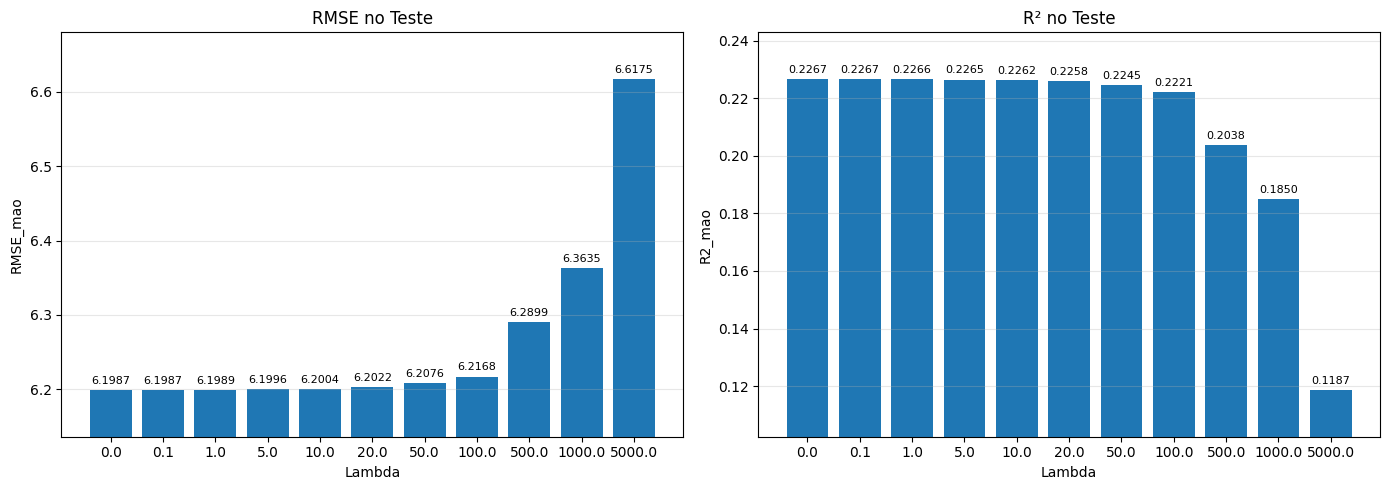

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lambdas = parametres["lambda"].astype(str)

colunas = ["RMSE_mao", "R2_mao"]
titulos = ["RMSE no Teste", "R² no Teste"]

for ax, coluna, titulo in zip(axes, colunas, titulos):
    valores = parametres[coluna].to_numpy()

    barras = ax.bar(lambdas, valores)

    # Aproximar os limites para destacar diferenças
    margem = max(np.ptp(valores) * 0.15, 0.001)
    ax.set_ylim(min(valores) - margem, max(valores) + margem)

    # Mostrar valores nas barras
    ax.bar_label(barras, fmt="%.4f", padding=3, fontsize=8)

    ax.set_title(titulo)
    ax.set_xlabel("Lambda")
    ax.set_ylabel(coluna)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## PLS ou PCR

Utilize os preditores transformados no conjunto de treinamento para ajustar um modelo de regressão PLS ou PCR e teste o modelo usando o conjunto de teste (lembre-se de aplicar o mesmo pré-processamento utilizado no conjunto de treinamento). Determine o número ideal de componentes por meio de validação cruzada de 5 ou 10 partes (k-fold), com base no RMSE (nesta etapa, utilize apenas o conjunto de treinamento). Descreva o processo (apresente o perfil da validação cruzada, tanto em termos de RMSE quanto de R²). Informe a precisão (RMSE e R²) obtida no conjunto de teste.

###Preparação dos dados

In [ ]:
# Utilizando a mesma divisão da equipe
X_pcr_treino = df_treino.drop(columns=['BMI', 'b0'], errors='ignore').copy()
X_pcr_teste = df_teste.drop(columns=['BMI', 'b0'], errors='ignore').copy()

y_pcr_treino = df_treino['BMI'].copy()
y_pcr_teste = df_teste['BMI'].copy()

# Colunas que receberão tratamento de assimetria
colunas_skew = ['PhysHlth', 'MentHlth']

print("Treinamento:", X_pcr_treino.shape)
print("Teste:", X_pcr_teste.shape)

Treinamento: (4500, 21)
Teste: (1500, 21)


###Definindo o modelo PCR

In [ ]:
def criar_modelo_pcr(n_componentes):

    # Transformação Yeo-Johnson
    preprocessamento = ColumnTransformer(
        transformers=[
            (
                'skewness',
                PowerTransformer(
                    method='yeo-johnson',
                    standardize=False
                ),
                colunas_skew
            )
        ],
        remainder='passthrough'
    )

    # Pipeline completo do PCR
    modelo = Pipeline([
        ('preprocessamento', preprocessamento),
        ('padronizacao', StandardScaler()),
        ('pca', PCA(n_components=n_componentes)),
        ('regressao', LinearRegression())
    ])

    return modelo

###Validação cruzada com K-Fold

In [ ]:
# Quantidade de partições
k = 10

# Número máximo de componentes
max_componentes = X_pcr_treino.shape[1]

# Configuração da validação cruzada
kf = KFold(
    n_splits=k,
    shuffle=True,
    random_state=42
)

resultados_pcr = []

# Testando diferentes números de componentes
for n in range(1, max_componentes + 1):

    rmse_folds = []
    r2_folds = []

    for idx_treino, idx_validacao in kf.split(X_pcr_treino):

        X_train = X_pcr_treino.iloc[idx_treino]
        X_valid = X_pcr_treino.iloc[idx_validacao]

        y_train = y_pcr_treino.iloc[idx_treino]
        y_valid = y_pcr_treino.iloc[idx_validacao]

        # Criando e treinando PCR
        modelo = criar_modelo_pcr(n)
        modelo.fit(X_train, y_train)

        # Predição
        y_pred = modelo.predict(X_valid)

        # Métricas
        rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
        r2 = r2_score(y_valid, y_pred)

        rmse_folds.append(rmse)
        r2_folds.append(r2)

    resultados_pcr.append({
        'Componentes': n,
        'RMSE': np.mean(rmse_folds),
        'R2': np.mean(r2_folds)
    })

resultados_pcr = pd.DataFrame(resultados_pcr)

display(resultados_pcr)

,Componentes,RMSE,R2
0,1,6.694931,0.090585
1,2,6.694951,0.090558
2,3,6.694886,0.090521
3,4,6.697604,0.089787
4,5,6.684026,0.093559
5,6,6.608954,0.113291
6,7,6.601180,0.115548
7,8,6.603156,0.115003
8,9,6.589148,0.118946
9,10,6.589648,0.118629


###Seleção do número ideal de componentes

In [ ]:
# Selecionando o menor RMSE médio
melhor_idx = resultados_pcr['RMSE'].idxmin()

melhor_n = int(
    resultados_pcr.loc[melhor_idx, 'Componentes']
)

melhor_rmse = resultados_pcr.loc[melhor_idx, 'RMSE']
melhor_r2 = resultados_pcr.loc[melhor_idx, 'R2']

print("===== MELHOR CONFIGURAÇÃO PCR =====")
print(f"Número de componentes: {melhor_n}")
print(f"RMSE médio (CV): {melhor_rmse:.4f}")
print(f"R² médio (CV): {melhor_r2:.4f}")

===== MELHOR CONFIGURAÇÃO PCR =====
Número de componentes: 20
RMSE médio (CV): 6.4104
R² médio (CV): 0.1663


###Gráficos da validação cruzada

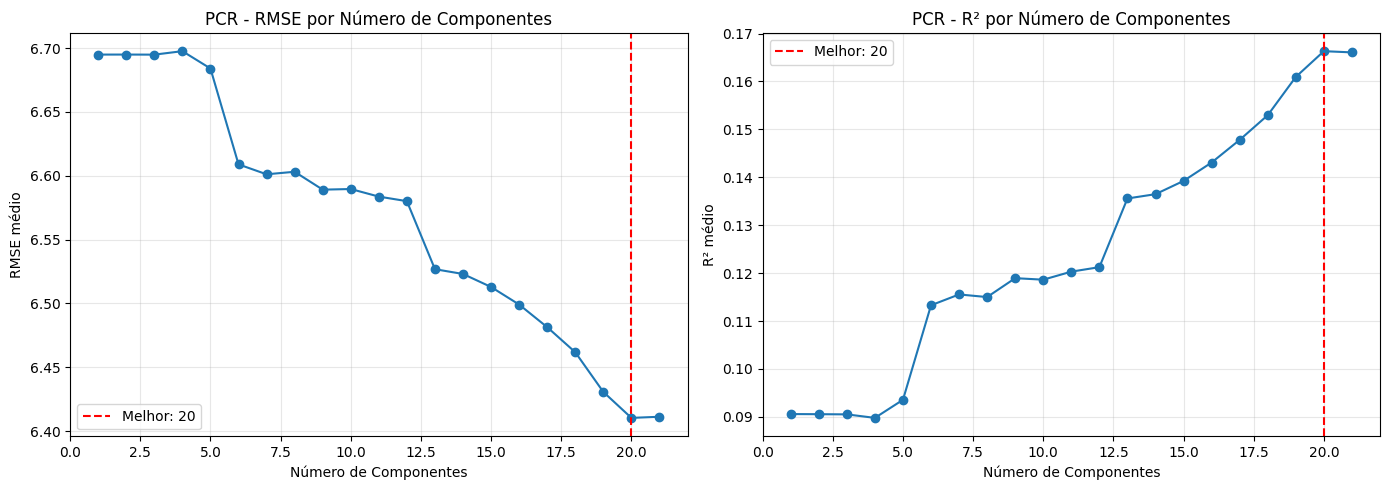

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico RMSE
axes[0].plot(
    resultados_pcr['Componentes'],
    resultados_pcr['RMSE'],
    marker='o'
)

axes[0].axvline(
    melhor_n,
    color='red',
    linestyle='--',
    label=f'Melhor: {melhor_n}'
)

axes[0].set_title('PCR - RMSE por Número de Componentes')
axes[0].set_xlabel('Número de Componentes')
axes[0].set_ylabel('RMSE médio')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfico R²
axes[1].plot(
    resultados_pcr['Componentes'],
    resultados_pcr['R2'],
    marker='o'
)

axes[1].axvline(
    melhor_n,
    color='red',
    linestyle='--',
    label=f'Melhor: {melhor_n}'
)

axes[1].set_title('PCR - R² por Número de Componentes')
axes[1].set_xlabel('Número de Componentes')
axes[1].set_ylabel('R² médio')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

###Treinamento e teste do modelo PCR

In [ ]:
# Criando modelo com o número ideal de componentes
modelo_pcr = criar_modelo_pcr(melhor_n)

# Treinando com todos os dados de treinamento
modelo_pcr.fit(X_pcr_treino, y_pcr_treino)

# Predição no conjunto de teste
y_pred_pcr = modelo_pcr.predict(X_pcr_teste)

# Métricas usando funções da equipe
rmse_pcr_mao = RMSE_calculo(y_pcr_teste, y_pred_pcr)
r2_pcr_mao = r2_calculo(y_pcr_teste, y_pred_pcr)

# Métricas utilizando sklearn
rmse_pcr = np.sqrt(
    mean_squared_error(y_pcr_teste, y_pred_pcr)
)

r2_pcr = r2_score(y_pcr_teste, y_pred_pcr)

print("===== RESULTADOS DO PCR =====")
print(f"Componentes selecionados: {melhor_n}")

print("\nCálculos da equipe:")
print(f"RMSE: {rmse_pcr_mao:.4f}")
print(f"R²: {r2_pcr_mao:.4f}")

print("\nFunções sklearn:")
print(f"RMSE: {rmse_pcr:.4f}")
print(f"R²: {r2_pcr:.4f}")

===== RESULTADOS DO PCR =====
Componentes selecionados: 20

Cálculos da equipe:
RMSE: 6.2024
R²: 0.2258

Funções sklearn:
RMSE: 6.2024
R²: 0.2258


###Comparação com a validação cruzada do sklearn

In [ ]:
# Validação com funções prontas
modelo_cv = criar_modelo_pcr(melhor_n)

scores = cross_validate(
    modelo_cv,
    X_pcr_treino,
    y_pcr_treino,
    cv=kf,
    scoring=[
        'neg_root_mean_squared_error',
        'r2'
    ]
)

rmse_cv_sklearn = -scores[
    'test_neg_root_mean_squared_error'
].mean()

r2_cv_sklearn = scores['test_r2'].mean()

print("===== COMPARAÇÃO K-FOLD =====")

print("\nImplementação manual:")
print(f"RMSE: {melhor_rmse:.4f}")
print(f"R²: {melhor_r2:.4f}")

print("\nScikit-learn:")
print(f"RMSE: {rmse_cv_sklearn:.4f}")
print(f"R²: {r2_cv_sklearn:.4f}")

===== COMPARAÇÃO K-FOLD =====

Implementação manual:
RMSE: 6.4104
R²: 0.1663

Scikit-learn:
RMSE: 6.4104
R²: 0.1663


## Rede Neural

Utilize os preditores transformados no conjunto de treinamento para construir um modelo de rede neural para regressão e teste o modelo usando o conjunto de teste (lembre-se de aplicar o mesmo pré-processamento utilizado no conjunto de treinamento). Apresente a precisão (RMSE e R²) obtida no conjunto de teste. O modelo não linear apresenta um desempenho superior ao do modelo linear que você desenvolveu anteriormente? Em caso afirmativo, o que isso pode indicar sobre a relação subjacente entre os preditores e a variável resposta?

### Definindo e separando os parâmetros

In [ ]:
#DEFININDO PARAMETROS
df_treino_rede_neural, lambdas_rede = tratamento_skewness(df_treino)
df_teste_rede_neural, _ = tratamento_skewness(df_teste, lambdas_rede)

# Separando atributos de entrada e variável alvo

X_treino = df_treino_rede_neural.drop(columns=['BMI'])
y_treino = df_treino_rede_neural['BMI']

X_teste = df_teste_rede_neural.drop(columns=['BMI'])
y_teste = df_teste_rede_neural['BMI']

### Padronização dos atributos

In [ ]:
scaler = StandardScaler()

# Ajusta o scaler no treinamento
X_treino_padronizado = scaler.fit_transform(X_treino)

# Aplica a mesma transformação no teste
X_teste_padronizado = scaler.transform(X_teste)

### Definindo a rede neural

In [ ]:
rede_neural = MLPRegressor(
    hidden_layer_sizes=(128),
    activation='relu',
    solver='adam',
    max_iter=10000,
    random_state=42
)


### Treinando

In [ ]:
rede_neural.fit(X_treino_padronizado, y_treino)


MLPRegressor(hidden_layer_sizes=128, max_iter=10000, random_state=42)

### Prevendo o conjunto de testes

In [ ]:
y_pred = rede_neural.predict(X_teste_padronizado)

### Avaliando Modelo

In [ ]:
# Cálculos usando funções nossas
RMSE_mao = RMSE_calculo(y_teste, y_pred)
R2_mao = r2_calculo(y_teste, y_pred)

# Cálculos usando função pronta
RMSE = np.sqrt(mean_squared_error(y_teste, y_pred))
R2 = r2_score(y_teste, y_pred)

print("===== RESULTADOS DA REDE NEURAL =====")
print(f"RMSE_mão: {RMSE_mao:.4f}")
print(f"R²_mão: {R2_mao:.4f}")
print(f"RMSE: {RMSE_mao:.4f}")
print(f"R²: {R2_mao:.4f}")

# Informações do treinamento
print(f"Iterações realizadas: {rede_neural.n_iter_}")
print(f"Épocas máximas: {rede_neural.max_iter}")
print(f"Loss final: {rede_neural.loss_}")
print(f"Número de camadas: {rede_neural.n_layers_}")
print(f"Número de neurônios na saída: {rede_neural.n_outputs_}")
print(f"Função de ativação: {rede_neural.activation}")
print(f"Otimizador: {rede_neural.solver}")

===== RESULTADOS DA REDE NEURAL =====
RMSE_mão: 6.9802
R²_mão: 0.0194
RMSE: 6.9802
R²: 0.0194
Iterações realizadas: 1337
Épocas máximas: 10000
Loss final: 10.322133130050497
Número de camadas: 3
Número de neurônios na saída: 1
Função de ativação: relu
Otimizador: adam


### Plotando os resultados

In [ ]:
resultados_rede_neural = pd.DataFrame({
    'Arquitetura': [
        '3',
        '6',
        '12',
        '32',
        '64',
        '128',
        '64-32',
        '128-64-32'
    ],
    'RMSE': [
        6.3111,
        6.1480,
        6.2963,
        6.2974,
        6.5138,
        6.9414,
        8.2057,
        8.8890
    ],
    'R2': [
        0.1946,
        0.2356,
        0.1983,
        0.1980,
        0.1420,
        0.0256,
        -0.3616,
        -0.5979
    ],
    'Iteracoes': [
        1566,
        890,
        634,
        698,
        1186,
        1024,
        773,
        331
    ],
    'Loss_final': [
        20.940939705562815,
        19.391878965133795,
        19.089307122320818,
        16.63936591769602,
        14.102071444189768,
        11.025561513448524,
        8.2684063339366855,
        3.35094132294655
    ]
})

resultados_rede_neural

,Arquitetura,RMSE,R2,Iteracoes,Loss_final
0,3,6.3111,0.1946,1566,20.940940
1,6,6.1480,0.2356,890,19.391879
2,12,6.2963,0.1983,634,19.089307
3,32,6.2974,0.1980,698,16.639366
4,64,6.5138,0.1420,1186,14.102071
5,128,6.9414,0.0256,1024,11.025562
6,64-32,8.2057,-0.3616,773,8.268406
7,128-64-32,8.8890,-0.5979,331,3.350941


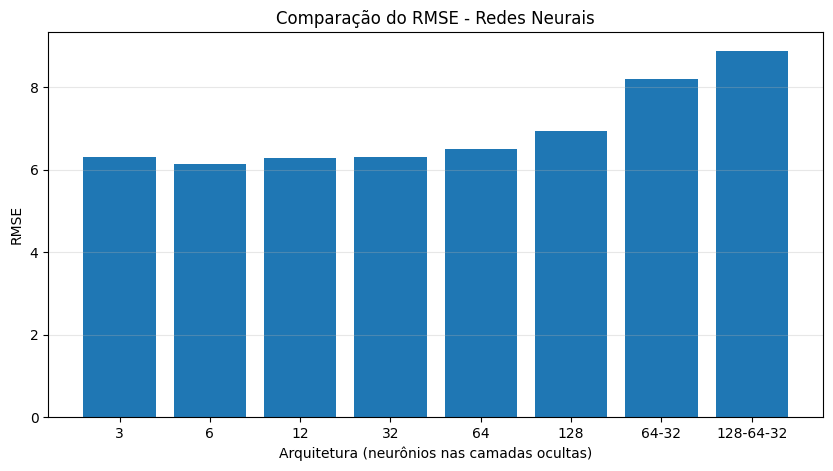

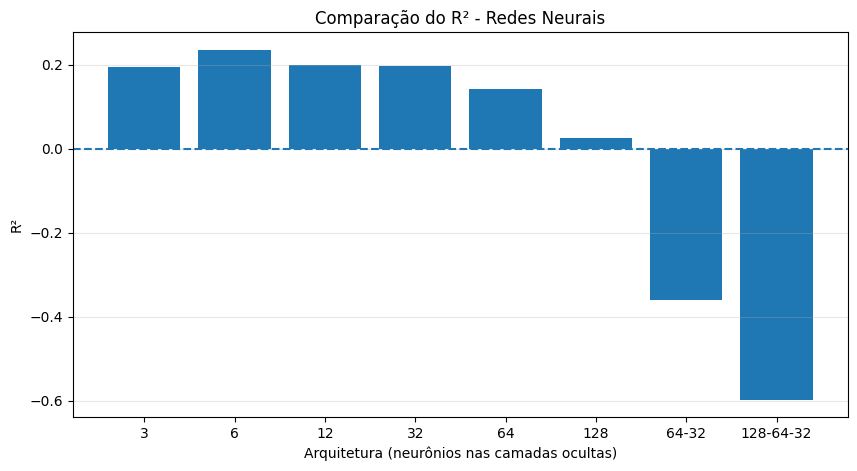

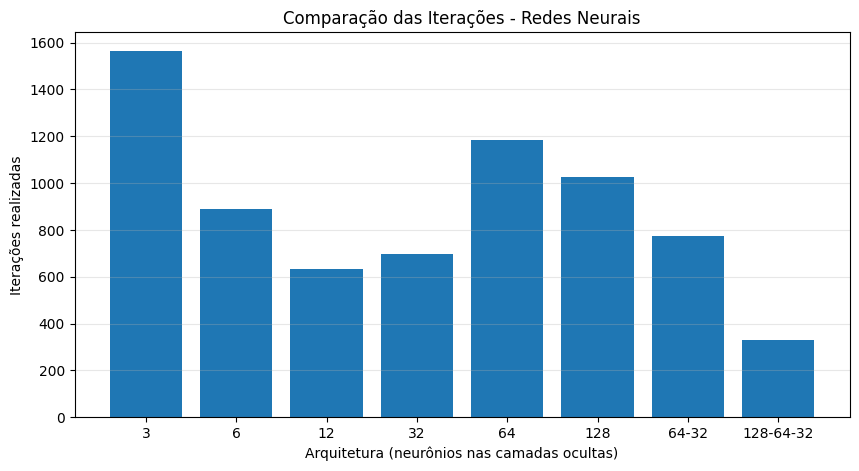

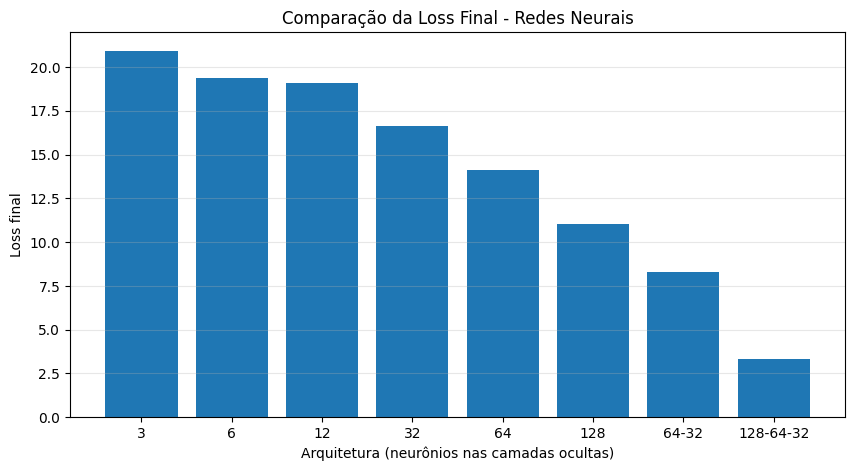

In [ ]:
# Comparação do RMSE
plt.figure(figsize=(10, 5))

plt.bar(
    resultados_rede_neural['Arquitetura'],
    resultados_rede_neural['RMSE']
)

plt.title('Comparação do RMSE - Redes Neurais')
plt.xlabel('Arquitetura (neurônios nas camadas ocultas)')
plt.ylabel('RMSE')

plt.grid(axis='y', alpha=0.3)
plt.show()


# Comparação do R²
plt.figure(figsize=(10, 5))

plt.bar(
    resultados_rede_neural['Arquitetura'],
    resultados_rede_neural['R2']
)

plt.title('Comparação do R² - Redes Neurais')
plt.xlabel('Arquitetura (neurônios nas camadas ocultas)')
plt.ylabel('R²')

plt.axhline(y=0, linestyle='--')

plt.grid(axis='y', alpha=0.3)
plt.show()

# ============================================
# COMPARAÇÃO DAS ITERAÇÕES
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    resultados_rede_neural['Arquitetura'],
    resultados_rede_neural['Iteracoes']
)

plt.title('Comparação das Iterações - Redes Neurais')
plt.xlabel('Arquitetura (neurônios nas camadas ocultas)')
plt.ylabel('Iterações realizadas')

plt.grid(axis='y', alpha=0.3)
plt.show()


# ============================================
# COMPARAÇÃO DA LOSS FINAL
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    resultados_rede_neural['Arquitetura'],
    resultados_rede_neural['Loss_final']
)

plt.title('Comparação da Loss Final - Redes Neurais')
plt.xlabel('Arquitetura (neurônios nas camadas ocultas)')
plt.ylabel('Loss final')

plt.grid(axis='y', alpha=0.3)
plt.show()